In [1]:
from IPython.utils import io
import tqdm.notebook
import os, os.path, sys, random, subprocess
total = 100
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      !pip install py3Dmol
      !pip install rdkit
      pbar.update(50)
      from rdkit import Chem
      from rdkit.Chem import Draw
      from rdkit.Chem.Draw import IPythonConsole
      from rdkit.Chem import AllChem # import the AllChem submodule from the Chem module
      from rdkit.Chem import rdDistGeom
      from rdkit.Chem import rdDepictor
      from IPython.display import Image
      import py3Dmol


      pbar.update(50)

  0%|          | 0/100 [00:00<?, ?it/s]

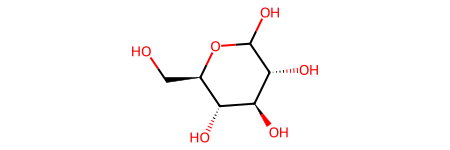

In [2]:
glucose = Chem.MolFromSmiles('OC[C@H]1OC(O)[C@@H]([C@H]([C@@H]1O)O)O')
glucose

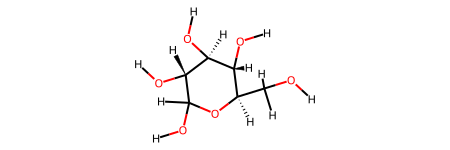

In [3]:
glucose_H = Chem.AddHs(glucose)
glucose_H

In [4]:
glucose_embed = AllChem.EmbedMolecule(glucose_H)
#glucose_embed

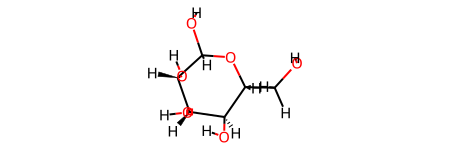

In [5]:
glucose_H

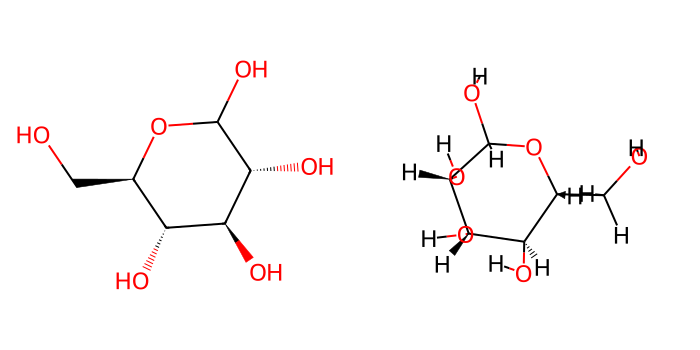

In [6]:
Draw.MolsToGridImage((glucose, glucose_H), subImgSize=(350,350), molsPerRow=2)

#pymol

In [10]:
ps = rdDistGeom.ETKDGv3()
ps.clearConfs= False
cid = rdDistGeom.EmbedMolecule(glucose_H,ps)

In [9]:
cid

1

Imprimimos los conformero

In [14]:
v = py3Dmol.view(width=400,height=400)
v.removeAllModels()
IPythonConsole.addMolToView(glucose_H,v,confId=0)
v.setStyle({'stick':{'colorscheme':'greenCarbon'}})
v.zoomTo()
v.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [16]:
v = py3Dmol.view(width=400,height=400)
v.removeAllModels()
IPythonConsole.addMolToView(glucose_H,v,confId=1) # Se enfoca al segundo conformero
v.setStyle({'model': 0, 'stick':{'colorscheme':'pinkCarbon'}})
v.zoomTo()
v.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [17]:
# Vista superpuesta (ambos conformeros con distinto color)
vj = py3Dmol.view(width=400, height=400)
vj.removeAllModels()

# Cargar el conformero 0 y definir su estilo base
IPythonConsole.addMolToView(glucose_H, vj, confId=0)
IPythonConsole.addMolToView(glucose_H, vj, confId=1)

# Cargar el conformero 1 y AÑADIR su estilo sin borrar el anterior
vj.setStyle({'model': 0}, {'stick': {'colorscheme': 'greenCarbon'}})
vj.addStyle({'model': 1}, {'stick': {'colorscheme': 'pinkCarbon'}})

vj.zoomTo()
vj.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [18]:
#UNA MANERA de ALINEAR LOS CONFORMEROS

# Align conformers 1 and 2
from rdkit.Chem import rdMolAlign

# Get the conformers
conf1 = glucose_H.GetConformer(0)
conf2 = glucose_H.GetConformer(1)


# Perform the alignment
rdMolAlign.AlignMol(glucose_H, glucose_H, 1, 0)


# Visualize the aligned conformers
v1 = py3Dmol.view(width=400,height=400)
v1.removeAllModels()
IPythonConsole.addMolToView(glucose_H,v1,confId=0)
IPythonConsole.addMolToView(glucose_H,v1,confId=1)
v1.setStyle({'model': 0}, {'stick': {'colorscheme': 'greenCarbon'}})

v1.addStyle({'model': 1}, {'stick': {'colorscheme': 'pinkCarbon'}})
v1.zoomTo()
v1.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [19]:
# # Vamos a alinear los conformeros


# # Generamos multiples conformeros
# num_conformers =  5 # Adjust the number of conformers as needed
# rdDepictor.Compute2DCoords(glucose_H)
# AllChem.EmbedMultipleConfs(glucose_H, numConfs=num_conformers, params=AllChem.ETKDG())

# # Alineamos los confórmeros a el primero cofórmero (confId=0)
# ref_conf = glucose_H.GetConformer(0)
# for i in range(1, num_conformers):
#     current_conf = glucose_H.GetConformer(i)
#     AllChem.AlignMol(glucose_H, glucose_H, prbCid=i, refCid=0)


# # Visualizamos multiples confórmeros en un slo visor v2
# v2 = py3Dmol.view(width=600, height=400)
# v2.removeAllModels()
# for i in range(num_conformers):
#     IPythonConsole.addMolToView(glucose_H, v2, confId=i)
#     style = {'stick': {}}
#     if i == 0:
#         style['stick']['colorscheme'] = 'blueCarbon'
#     else:
#         style['stick']['colorscheme'] = 'orangeCarbon'
#     v2.addStyle({'model': i}, style)

# v2.zoomTo()
# v2.show()

In [21]:
# Generamos múltiples confórmeros
num_conformers = 5
rdDepictor.Compute2DCoords(glucose_H)
AllChem.EmbedMultipleConfs(glucose_H, numConfs=num_conformers, params=AllChem.ETKDG())

# Alineamos los confórmeros al primer confórmero (confId=0)
ref_conf = glucose_H.GetConformer(0)
for i in range(1, num_conformers):
    current_conf = glucose_H.GetConformer(i)
    AllChem.AlignMol(glucose_H, glucose_H, prbCid=i, refCid=0)

# Visualizamos múltiples confórmeros
v2 = py3Dmol.view(width=600, height=400)
v2.removeAllModels()

# PASO 1: Cargar todos los confórmeros primero
for i in range(num_conformers):
    IPythonConsole.addMolToView(glucose_H, v2, confId=i)

# PASO 2: Borrar el estilo 'stick' que RDKit agrega por defecto
v2.setStyle({}, {})

# PASO 2: Aplicar estilos a cada modelo al final
for i in range(num_conformers):
    colorscheme = 'grayCarbon' if i == 0 else 'blueCarbon'

    if i == 0:
        v2.setStyle({'model': i}, {'stick': {'colorscheme': colorscheme}})
    else:
        v2.addStyle({'model': i}, {'stick': {'colorscheme': colorscheme}})

v2.zoomTo()
v2.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [22]:
# # Visualizamos múltiples confórmeros
# v2 = py3Dmol.view(width=1600, height=1400)
# v2.removeAllModels()

# # PASO 1: Cargar todos los confórmeros primero
# for i in range(num_conformers):
#     IPythonConsole.addMolToView(glucose_H, v2, confId=i)

# # PASO 2: Borrar el estilo 'stick' que RDKit agrega por defecto
# v2.setStyle({}, {})

# # PASO 3: Aplicar el estilo 'line' a cada modelo
# for i in range(num_conformers):
#     colorscheme = 'blueCarbon' if i == 0 else 'greenCarbon'
#     v2.addStyle({'model': i}, {'stick': {'colorscheme': colorscheme, 'linewidth': 2}})

# v2.zoomTo()
# v2.show()

# Distintas moleculas

Vamos a comparar distintas moléculas

In [24]:
manose = Chem.MolFromSmiles('OC[C@H]1OC(O)[C@@H](O)[C@@H](O)[C@@H]1O')
mol2 = Chem.AddHs(manose)
AllChem.EmbedMolecule(mol2)
cid = rdDistGeom.EmbedMolecule(mol2,ps)
v3 = py3Dmol.view(width=400,height=400)
v3.removeAllModels()

IPythonConsole.addMolToView(mol2, v3, confId=0)
v3.setStyle({'stick':{'colorscheme':'pinkCarbon'}}) # Style as sticks for better visualization
v3.zoomTo()
v3.setStyle({'stick':{'colorscheme':'greenCarbon'}})
print('Manosa')
v3.show()


Manosa


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Vamos a comparar la glucosa y la manosa

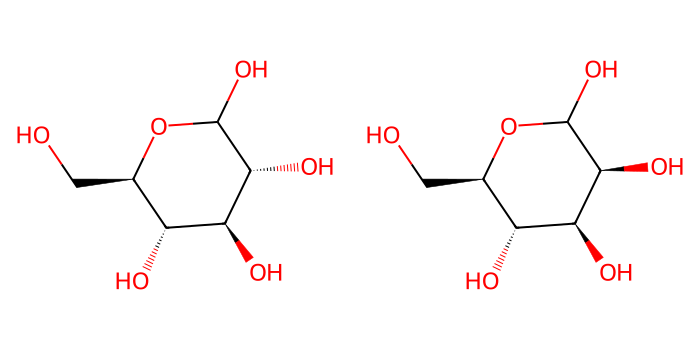

In [25]:
# Comparamos estructuras 2D
img = Draw.MolsToGridImage((glucose, manose), subImgSize=(350,350), molsPerRow=2)
display(img)

In [28]:
# mol1 = glucose_H
# cid = rdDistGeom.EmbedMolecule(mol2,ps)
# v4 = py3Dmol.view(width=400,height=400)
# v4.removeAllModels()

# lis = [mol1, mol2]

# # Display the aligned molecules using py3Dmol
# rmsd = AllChem.AlignMol(mol2, mol1)

# # Add the first molecule (reference)
# IPythonConsole.addMolToView(mol1, v4, confId=0)
# #v4.setStyle({'stick':{'colorscheme':'pinkCarbon'}}) # Target the second model
# v4.setStyle({'model': 0}, {'stick':{'colorscheme':'grayCarbon'}})


# # Add the second molecule (aligned)
# IPythonConsole.addMolToView(mol2, v4, confId=0)
# #v4.setStyle({'stick':{'colorscheme':'orangeCarbon'}}) # Style as sticks for better visualization
# v4.addStyle({'model': 0}, {'stick':{'colorscheme':'orangeCarbon'}})


# v4.zoomTo()
# v4.show()



mol1 = glucose_H
cid = rdDistGeom.EmbedMolecule(mol2,ps)
v4 = py3Dmol.view(width=1400,height=1400)
v4.removeAllModels()

lis = [mol1, mol2]

# Display the aligned molecules using py3Dmol
rmsd = AllChem.AlignMol(mol2, mol1)

# Add the first molecule (reference)
IPythonConsole.addMolToView(mol1, v4, confId=0)
IPythonConsole.addMolToView(mol2, v4, confId=0)

#v4.setStyle({'stick':{'colorscheme':'pinkCarbon'}}) # Target the second model
v4.setStyle({'model': 0}, {'stick':{'colorscheme':'purpleCarbon'}})


# Add the second molecule (aligned)

#v4.setStyle({'stick':{'colorscheme':'orangeCarbon'}}) # Style as sticks for better visualization
v4.addStyle({'model': 1}, {'stick':{'colorscheme':'yellowCarbon'}})


v4.zoomTo()
v4.show()




print(f'')
print(f'RMSD: {rmsd:.2f}')

3Dmol.js failed to load for some reason. Please check your browser console for error messages.


RMSD: 1.29


In [29]:
# mol1 = glucose_H
# cid = rdDistGeom.EmbedMolecule(mol2, ps)
# v4 = py3Dmol.view(width=400, height=400)
# v4.removeAllModels()

# # Alineamos la manosa (mol2) con la glucosa (mol1)
# rmsd = AllChem.AlignMol(mol2, mol1)

# # 1. Glucosa (Modelo 0) -> Morado
# IPythonConsole.addMolToView(mol1, v4, confId=0)
# IPythonConsole.addMolToView(mol2, v4, confId=0)

# v4.setStyle({'model': 0}, {'stick': {'colorscheme': 'purpleCarbon'}})

# # 2. Manosa (Modelo 1) -> Amarillo

# v4.addStyle({'model': 1}, {'stick': {'colorscheme': 'yellowCarbon'}})

# v4.zoomTo()
# v4.show()

# print(f'RMSD: {rmsd:.2f}')

In [30]:
# mol1 = glucose_H
# cid = rdDistGeom.EmbedMolecule(mol2, ps)
# v4 = py3Dmol.view(width=400, height=400)
# v4.removeAllModels()

# # 1. Alineamos la manosa (mol2) con la glucosa (mol1)
# rmsd = AllChem.AlignMol(mol2, mol1)

# # 2. Cargamos AMBAS moléculas PRIMERO
# IPythonConsole.addMolToView(mol1, v4, confId=0) # Modelo 0 (Glucosa)
# IPythonConsole.addMolToView(mol2, v4, confId=0) # Modelo 1 (Manosa)

# # 3. Aplicamos los estilos DESPUÉS de haber cargado ambas
# v4.setStyle({'model': 0}, {'stick': {'colorscheme': 'purpleCarbon'}}) # Morado
# v4.addStyle({'model': 1}, {'stick': {'colorscheme': 'yellowCarbon'}}) # Amarillo

# v4.zoomTo()
# v4.show()

# print(f'RMSD: {rmsd:.2f}')

Podemos invocar los distintos v en diferentres secciones del notebook

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

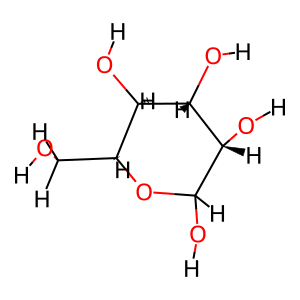

In [31]:
v3.show()#visualizamos la manosa
display(Draw.MolToImage(mol2))

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

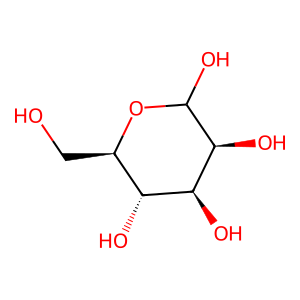

None

In [32]:
#display(Draw.MolToImage(glucose_H), v.show())
display(Draw.MolToImage(manose), v3.show())